# Séries Temporais, Econometria Financeira e Machine Learning — Petrobras (`PETR4`, 2000–2026)

**Estudo End-to-End de Econometria Financeira, Quebras Estruturais e Validação Walk-Forward**

---

### Visão Geral do Estudo
Este notebook apresenta uma investigação quantitativa completa das ações preferenciais da **Petrobras (`PETR4`)** ao longo de **26 anos (jan/2000 – nov/2026)**, estruturada em **5 Atos** e apoiada por módulos reprodutíveis em `src/`:

| Ato | Pilar Analítico | Técnicas e Entregas Principais |
| :--- | :--- | :--- |
| **1** | **Contexto Histórico & Volatilidade** | Pipeline causal diário e mensal (`yfinance` + IPEADATA + BCB SGS), separação *Close* vs. *Adj Close* (dividendos) e análise dos **5 marcos históricos (2006–2023)** |
| **2** | **Quebras Estruturais & CAPM Dinâmico** | CAPM e **Multifatorial (Ibovespa + Brent + USD/BRL)** com erros **HAC Newey-West**, **Beta Rolante (252d)** e **Teste F de Chow** pontual e rolante (estilo Quandt-Andrews) |
| **3** | **Estocástica & Estacionariedade** | Demonstração de **Correlação Espúria** (níveis vs. retornos), simulação **Passeio Aleatório vs. Ruído Branco**, bateria **ADF + KPSS** e painéis **ACF/PACF** |
| **4** | **Econometria Univariada & Multivariada** | Grid search AIC/BIC **Box-Jenkins (`ARIMA`)**, diagnóstico Ljung-Box/Jarque-Bera e **VAR** com ordenação Cholesky econômica, **Granger, IRF e FEVD** |
| **5** | **ML Benchmark, Data Leakage & Cenários** | Prova empírica de **Data Leakage**, **Walk-Forward (9 modelos)** estritamente causal e **Simulação de Cenários Macroeconômicos (12m)** com bandas de incerteza |

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.data_pipeline import HISTORICAL_EVENTS, build_datasets
from src.econometrics import (
    estimate_capm_and_multifactor,
    evaluate_historical_breaks,
    fit_var_and_granger,
    select_and_fit_arima,
    stationarity_report,
)
from src.ml_benchmark import (
    demonstrate_data_leakage,
    run_walk_forward_benchmark,
    simulate_macro_scenarios,
)
from src.visualization import (
    plot_arima_diagnostics,
    plot_benchmark_and_leakage,
    plot_capm_and_rolling_beta,
    plot_chow_structural_breaks,
    plot_historical_shocks_and_volatility,
    plot_macro_scenarios,
    plot_spurious_vs_returns,
    plot_stationarity_acf_pacf,
    plot_var_irf_fevd,
)

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
%matplotlib inline

FIG_DIR = Path("reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

---
## Ato 1 — Contexto Econômico, Pipeline de Dados e Regimes de Volatilidade (2000–2026)

Fundada em 1953, a **Petrobras** é uma sociedade de economia mista com controle estatal cujas ações preferenciais (`PETR4`) figuram entre os ativos mais líquidos da B3. Por combinar exposição a uma *commodity* global precificada em dólar (**Petróleo Brent**) com forte peso no **Ibovespa** e sensibilidade direta a decisões de governança e política de preços de combustíveis do acionista controlador (Governo Federal), `PETR4` é um laboratório privilegiado para estudar **quebras estruturais** e **regimes de risco**.

### Os 5 Marcos Históricos Analisados
1. **`2006-07-01` — Descoberta do Pré-Sal:** Anúncio das reservas em águas ultraprofundas reposiciona a companhia no cenário energético global, atraindo forte fluxo de capital e ciclo de investimentos.
2. **`2008-09-15` — Crise do *Subprime* (Lehman Brothers):** Contração global de liquidez e tombo abrupto das *commodities* e dos mercados emergentes.
3. **`2016-05-30` — Pós-Impeachment & Posse de Pedro Parente (PPI):** Após o choque da Operação Lava Jato e anos de controle artificial de preços de combustíveis, a nova gestão implementa o **Preço de Paridade de Importação (PPI)** e desalavancagem via venda de ativos.
4. **`2020-03-09` — Choque da COVID-19 & Guerra de Preços do Petróleo:** Colapso simultâneo de demanda global e disputa OPEP+, levando a um dos maiores saltos de volatilidade da história da B3.
5. **`2023-05-16` — Fim do PPI & Novo Regime de Dividendos:** Encerramento formal da paridade estrita de importação com manutenção de elevada geração de caixa e pagamento robusto de proventos, alterando o perfil de risco sistemático ($\beta$) do papel.

### Decisão Metodológica sobre Preço e Frequência
* **`petr4_close` (Preço de Tela Ajustado a Splits):** Útil para leitura visual da cotação histórica nominal da ação.
* **`petr4_adj_close` (Retorno Total Ajustado a Dividendos e JCP):** Essencial para modelagem financeira, CAPM e *backtesting*, pois a Petrobras distribuiu proventos extraordinários a partir de 2021 — ignorá-los distorceria severamente o retorno real do acionista.
* **Alinhamento Causal:** Dados de calendários distintos (Brent via IPEADATA 2000–2007 + `BZ=F` 2007–2026; PTAX USD/BRL e Selic via API SGS do Banco Central) são alinhados ao calendário de pregão da B3 usando exclusivamente *forward-fill* causal (zero *look-ahead*).

In [2]:
df_daily, df_monthly = build_datasets(
    raw_dir="data/raw",
    processed_dir="data/processed",
    force_download=False,
)

print(f"Base Diária : {df_daily.shape[0]:,} pregões | {df_daily.index.min().date()} até {df_daily.index.max().date()}")
print(f"Base Mensal : {df_monthly.shape[0]:,} meses   | {df_monthly.index.min().date()} até {df_monthly.index.max().date()}")
print("\nValores ausentes nas colunas centrais (diária):", int(df_daily.drop(columns=["vol_22d", "vol_252d"]).isna().sum().sum()))
print("Valores ausentes na base mensal:", int(df_monthly.isna().sum().sum()))

summary_stats = pd.DataFrame({
    "Retorno_Acumulado_%": [
        (df_daily["petr4_adj_close"].iloc[-1] / df_daily["petr4_adj_close"].iloc[0] - 1) * 100,
        (df_daily["petr4_close"].iloc[-1] / df_daily["petr4_close"].iloc[0] - 1) * 100,
        (df_daily["ibov_close"].iloc[-1] / df_daily["ibov_close"].iloc[0] - 1) * 100,
        np.expm1(df_daily["selic_daily_log"].sum()) * 100,
        (df_daily["brent_usd"].iloc[-1] / df_daily["brent_usd"].iloc[0] - 1) * 100,
    ],
    "Retorno_Anualizado_CAGR_%": [
        ((df_daily["petr4_adj_close"].iloc[-1] / df_daily["petr4_adj_close"].iloc[0]) ** (252 / len(df_daily)) - 1) * 100,
        ((df_daily["petr4_close"].iloc[-1] / df_daily["petr4_close"].iloc[0]) ** (252 / len(df_daily)) - 1) * 100,
        ((df_daily["ibov_close"].iloc[-1] / df_daily["ibov_close"].iloc[0]) ** (252 / len(df_daily)) - 1) * 100,
        np.expm1(df_daily["selic_daily_log"].mean() * 252) * 100,
        ((df_daily["brent_usd"].iloc[-1] / df_daily["brent_usd"].iloc[0]) ** (252 / len(df_daily)) - 1) * 100,
    ],
    "Volatilidade_Anualizada_%": [
        df_daily["ret_petr4"].std() * np.sqrt(252) * 100,
        df_daily["ret_petr4_nominal"].std() * np.sqrt(252) * 100,
        df_daily["ret_ibov"].std() * np.sqrt(252) * 100,
        df_daily["selic_daily_log"].std() * np.sqrt(252) * 100,
        df_daily["ret_brent_usd"].std() * np.sqrt(252) * 100,
    ],
}, index=["PETR4 Retorno Total (Adj Close)", "PETR4 Preço de Tela (Close)", "Ibovespa (^BVSP)", "Selic Acumulada (Renda Fixa)", "Petróleo Brent (USD)"])

display(summary_stats.round(2))

Base Diária : 6,744 pregões | 2000-01-05 até 2026-11-17
Base Mensal : 321 meses   | 2000-02-29 até 2026-10-31

Valores ausentes nas colunas centrais (diária): 0
Valores ausentes na base mensal: 0


,Retorno_Acumulado_%,Retorno_Anualizado_CAGR_%,Volatilidade_Anualizada_%
PETR4 Retorno Total (Adj Close),"4,361.9300",15.2500,41.1600
PETR4 Preço de Tela (Close),700.5100,8.0800,41.5100
Ibovespa (^BVSP),945.3500,9.1700,26.7900
Selic Acumulada (Renda Fixa),"2,197.0400",12.4200,0.2800
Petróleo Brent (USD),292.6600,5.2400,42.1300


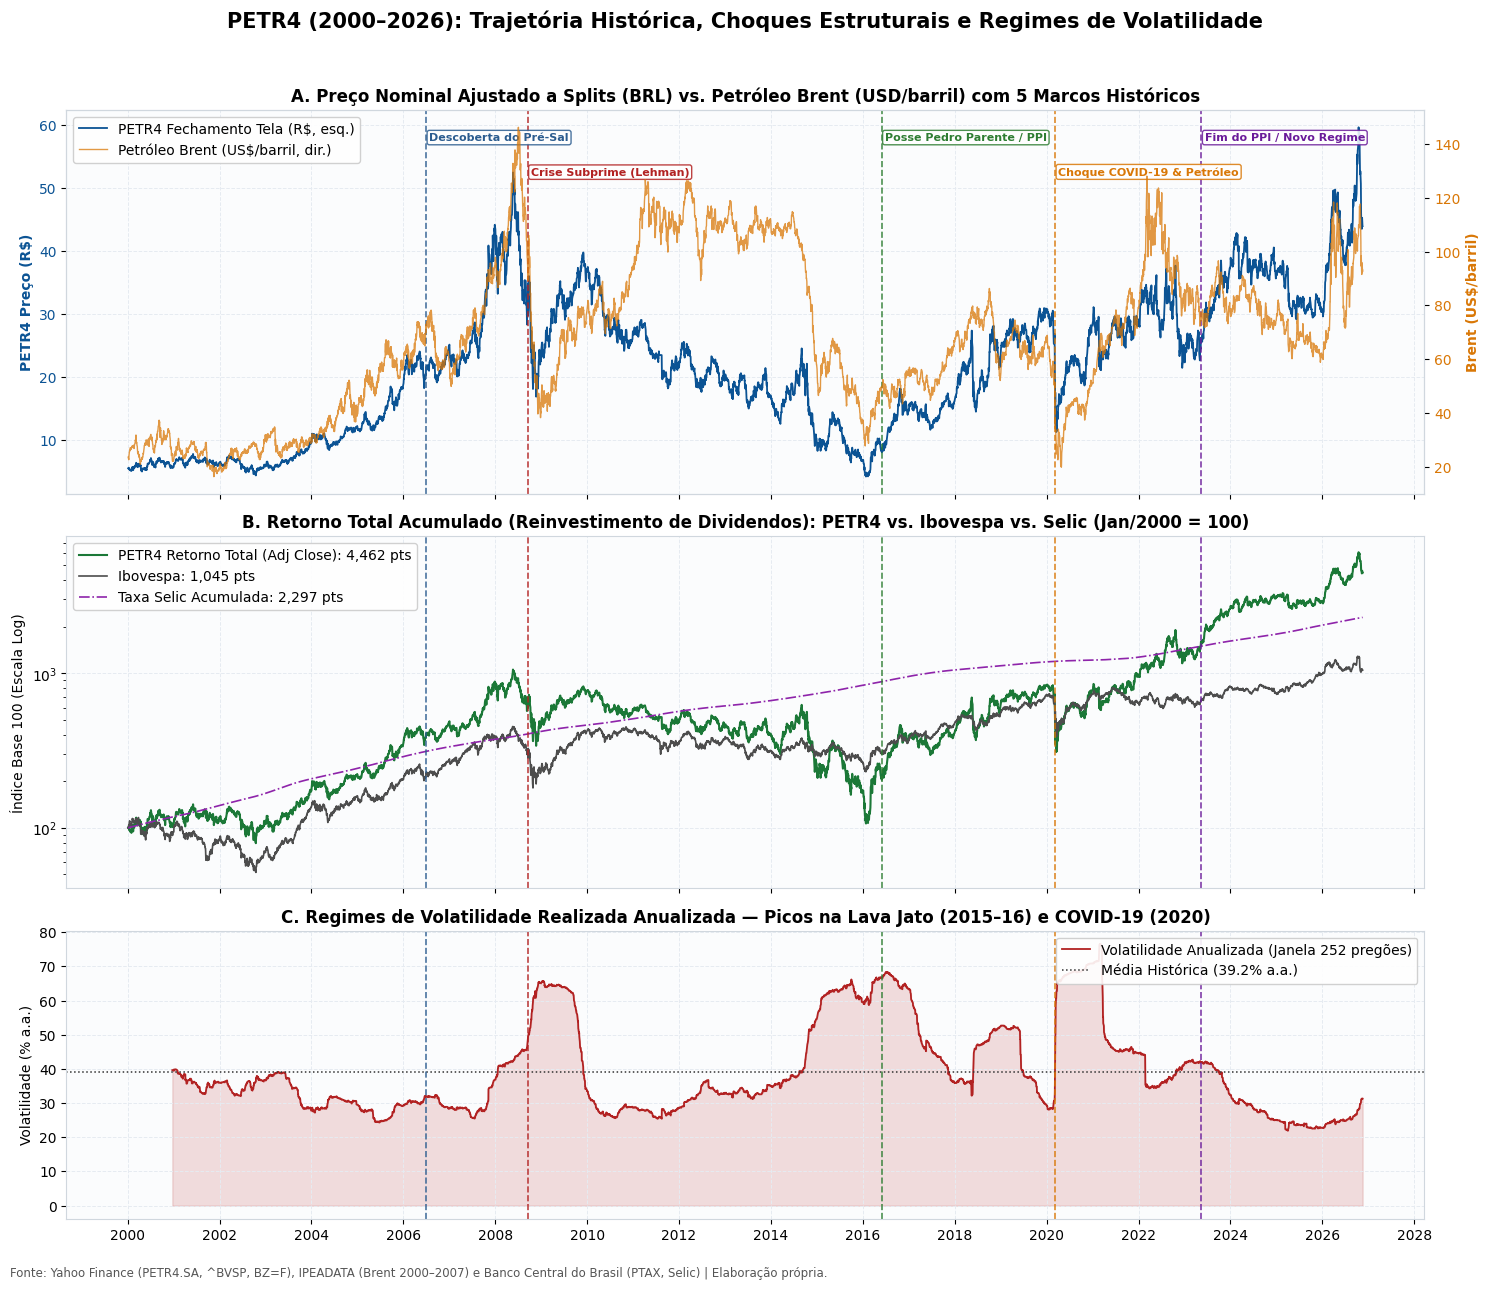

In [3]:
fig1 = plot_historical_shocks_and_volatility(
    df_daily,
    output_path=FIG_DIR / "01_historico_choques_volatilidade.png",
)
plt.show()

---
## Ato 2 — Análise Estrutural e Risco de Mercado: CAPM Dinâmico & Teste F de Chow

### 2.1 CAPM Clássico, CAPM Dinâmico e Modelo Multifatorial Macrofinanceiro
No **Capital Asset Pricing Model (CAPM)**, estimamos a sensibilidade sistemática ($\beta$) do excesso de retorno de `PETR4` em relação ao prêmio de risco de mercado (`Ibovespa` menos `Selic`):

$$R_{\text{PETR4},t} - R_{f,t} = \alpha + \beta_{\text{Ibov}}(R_{\text{Ibov},t} - R_{f,t}) + \varepsilon_t$$

Para capturar os canais específicos de receita e risco da Petrobras, ampliamos o modelo para uma especificação **Multifatorial Macrofinanceira** com erros-padrão robustos à heterocedasticidade e autocorrelação (**Newey-West HAC**):

$$R_{\text{PETR4},t} - R_{f,t} = \alpha + \beta_{\text{Ibov}}(R_{\text{Ibov},t} - R_{f,t}) + \beta_{\text{Brent}} \, r_{\text{Brent},t} + \beta_{\text{FX}} \, r_{\text{USD/BRL},t} + \varepsilon_t$$

In [4]:
capm_res = estimate_capm_and_multifactor(df_monthly, df_daily)

print("=== CAPM Clássico Mensal (Erros-Padrão HAC Newey-West) ===")
print(capm_res["capm_monthly"].summary().tables[1])
print(f"R² ajustado CAPM Mensal: {capm_res['capm_monthly'].rsquared_adj:.4f}")

print("\n=== Modelo Multifatorial Mensal (CAPM + Brent USD + Câmbio USD/BRL, HAC) ===")
print(capm_res["multifactor_monthly"].summary().tables[1])
print(f"R² ajustado Multifatorial Mensal: {capm_res['multifactor_monthly'].rsquared_adj:.4f}")

print("\n=== Evolução de Retorno, Volatilidade e Betas por Regime Político-Econômico (Base Diária) ===")
display(capm_res["regime_table"].round(3))

=== CAPM Clássico Mensal (Erros-Padrão HAC Newey-West) ===
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const           0.0059      0.004      1.390      0.165      -0.002       0.014
excess_ibov     1.2243      0.108     11.328      0.000       1.012       1.436
R² ajustado CAPM Mensal: 0.5519

=== Modelo Multifatorial Mensal (CAPM + Brent USD + Câmbio USD/BRL, HAC) ===
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.0042      0.004      1.068      0.286      -0.004       0.012
excess_ibov       1.0862      0.098     11.104      0.000       0.894       1.278
ret_brent_usd     0.2705      0.042      6.424      0.000       0.188       0.353
ret_usd_brl       0.0330      0.094      0.351      0.726      -0.151       0.217
R² ajustado Multifa

,Regime,Pregões,Retorno_Anual_%,Volatilidade_Anual_%,Beta_CAPM,R2_CAPM,Beta_Multi_Ibov,Beta_Multi_Brent,Beta_Multi_FX,R2_Multi
0,Pré-Descoberta (2000–2006),1681,23.1150,33.4010,0.7260,0.3920,0.7180,0.0440,-0.0310,0.3970
1,Pré-Sal & Subprime (2006–2014),1909,-3.6980,38.2150,0.9480,0.5350,0.9010,0.1190,0.0100,0.5470
2,Crise & Lava Jato (2014–2016),543,-15.9280,63.7150,1.9650,0.6520,1.8320,0.2100,-0.1500,0.6720
3,Era PPI & COVID (2016–2023),1734,33.9170,47.4090,1.4260,0.5920,1.3260,0.2180,0.0140,0.6270
4,Pós-PPI & Dividendos (2023–2026),877,35.2400,27.4880,0.6390,0.1720,0.7720,0.3220,0.2870,0.3970


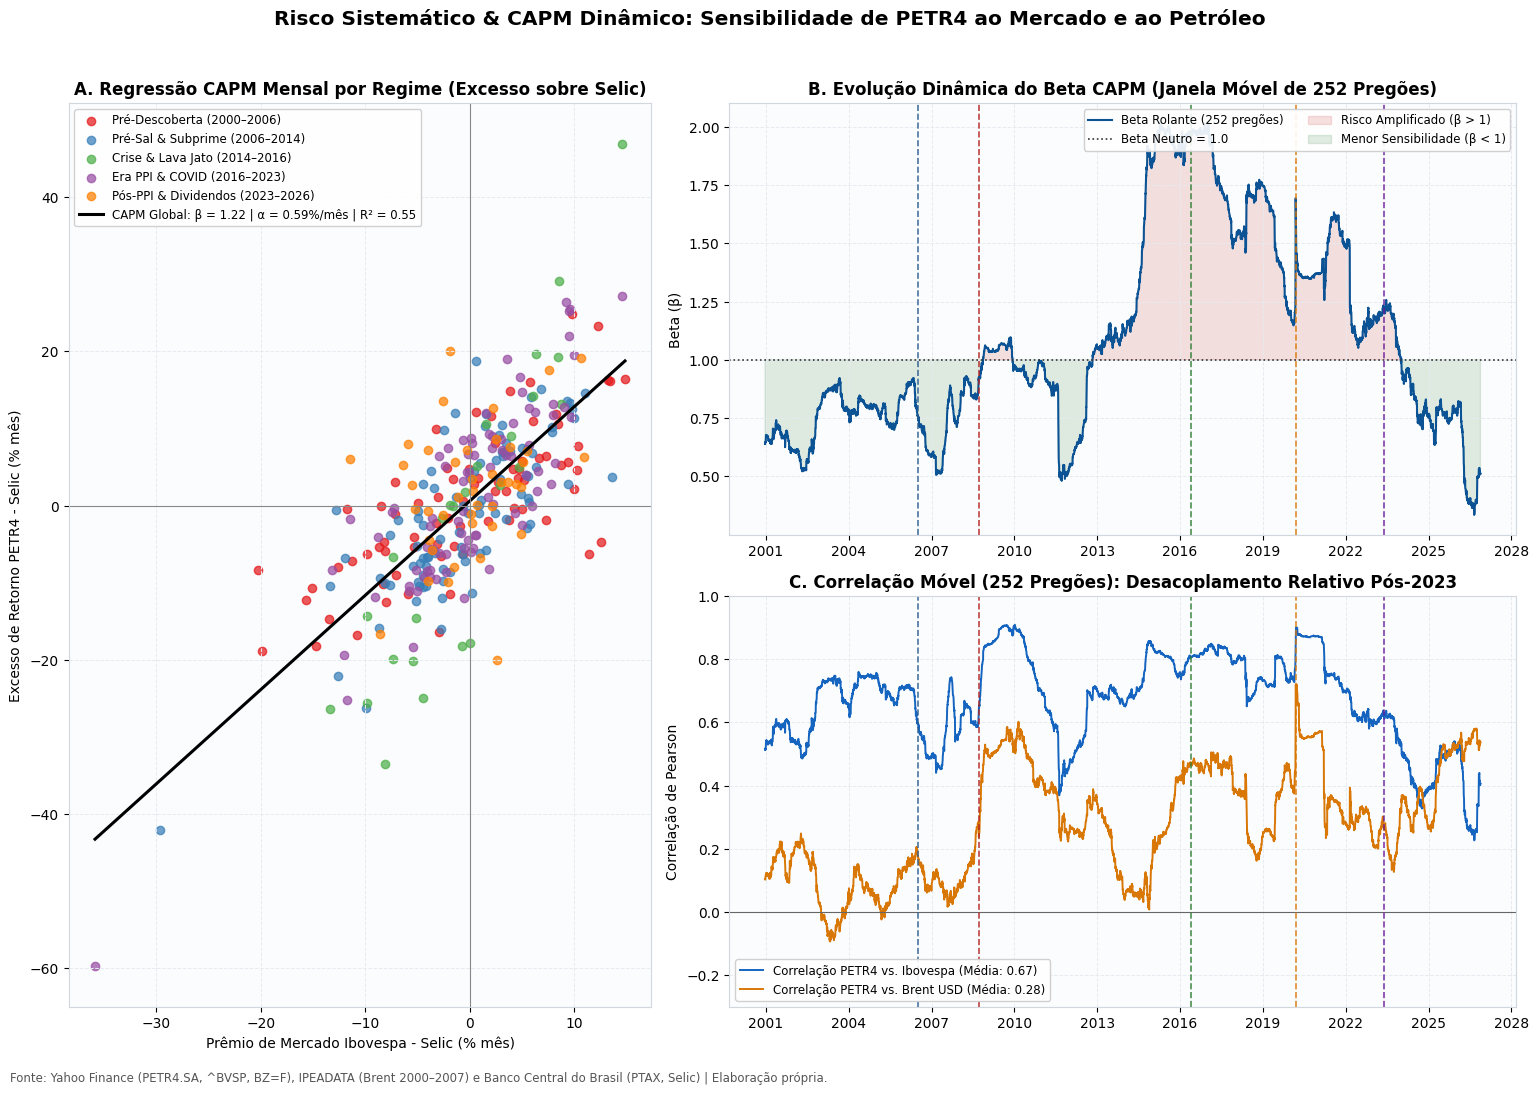

In [5]:
fig3 = plot_capm_and_rolling_beta(
    df_daily,
    df_monthly,
    capm_res,
    output_path=FIG_DIR / "03_capm_beta_rolante_correlacoes.png",
)
plt.show()

### 2.2 Teste de Quebra Estrutural de Chow
Para verificar formalmente se os parâmetros estruturais do ativo sofreram rupturas nos grandes choques históricos, implementamos a estatística $F$ exata do **Teste de Chow** via `statsmodels` OLS:

$$F = \frac{\left(SSR_{\text{restrito}} - (SSR_1 + SSR_2)\right) / k}{(SSR_1 + SSR_2) / (n_1 + n_2 - 2k)} \sim F_{k,\, n_1 + n_2 - 2k}$$

Avaliamos os **5 marcos históricos** sob duas lentes complementares:
* **Especificação A (Trajetória Local $\pm 252$ pregões):** Testa quebra de nível e inclinação no log-preço ($\ln P_t = \beta_0 + \beta_1 t + u_t$) ao redor de cada evento.
* **Especificação B (Modelo Multifatorial Completo):** Testa se o vetor de sensibilidades estruturais $(\alpha, \beta_{\text{Ibov}}, \beta_{\text{Brent}}, \beta_{\text{FX}})$ sofreu ruptura estatisticamente significativa antes vs. depois do marco histórico.

In [6]:
chow_table, rolling_chow = evaluate_historical_breaks(df_daily)
display(chow_table.round(4))

,Evento,Data_Marco,Especificação,N_Pré,N_Pós,F_Stat,F_Crit_1%,p_valor,Quebra_1%,Quebra_5%,Beta_Ibov_Pré,Beta_Ibov_Pós,Beta_Brent_Pré,Beta_Brent_Pós
0,Descoberta do Pré-Sal,2006-07-01,A: Trajetória Local ±252d (Log-Preço),252,252,195.4839,4.6478,0.0000,True,True,NaN,NaN,NaN,NaN
1,Descoberta do Pré-Sal,2006-07-01,B: Multifatorial Estrutural (Amostra Completa),1681,5063,76.6021,3.3220,0.0000,True,True,0.7183,1.1145,0.0440,0.2202
2,Crise Subprime (Lehman),2008-09-15,A: Trajetória Local ±252d (Log-Preço),252,252,303.1756,4.6478,0.0000,True,True,NaN,NaN,NaN,NaN
3,Crise Subprime (Lehman),2008-09-15,B: Multifatorial Estrutural (Amostra Completa),2229,4515,89.5134,3.3220,0.0000,True,True,0.7411,1.1542,0.0561,0.2257
4,Posse Pedro Parente / PPI,2016-05-30,A: Trajetória Local ±252d (Log-Preço),252,252,231.7373,4.6478,0.0000,True,True,NaN,NaN,NaN,NaN
5,Posse Pedro Parente / PPI,2016-05-30,B: Multifatorial Estrutural (Amostra Completa),4133,2611,51.4191,3.3220,0.0000,True,True,0.9256,1.2036,0.1051,0.2734
6,Choque COVID-19 & Petróleo,2020-03-09,A: Trajetória Local ±252d (Log-Preço),252,252,644.9843,4.6478,0.0000,True,True,NaN,NaN,NaN,NaN
7,Choque COVID-19 & Petróleo,2020-03-09,B: Multifatorial Estrutural (Amostra Completa),5076,1668,23.9182,3.3220,0.0000,True,True,0.9815,1.1061,0.1237,0.2771
8,Fim do PPI / Novo Regime,2023-05-16,A: Trajetória Local ±252d (Log-Preço),252,252,244.6851,4.6478,0.0000,True,True,NaN,NaN,NaN,NaN
9,Fim do PPI / Novo Regime,2023-05-16,B: Multifatorial Estrutural (Amostra Completa),5867,877,25.5493,3.3220,0.0000,True,True,1.0240,0.7722,0.1437,0.3225


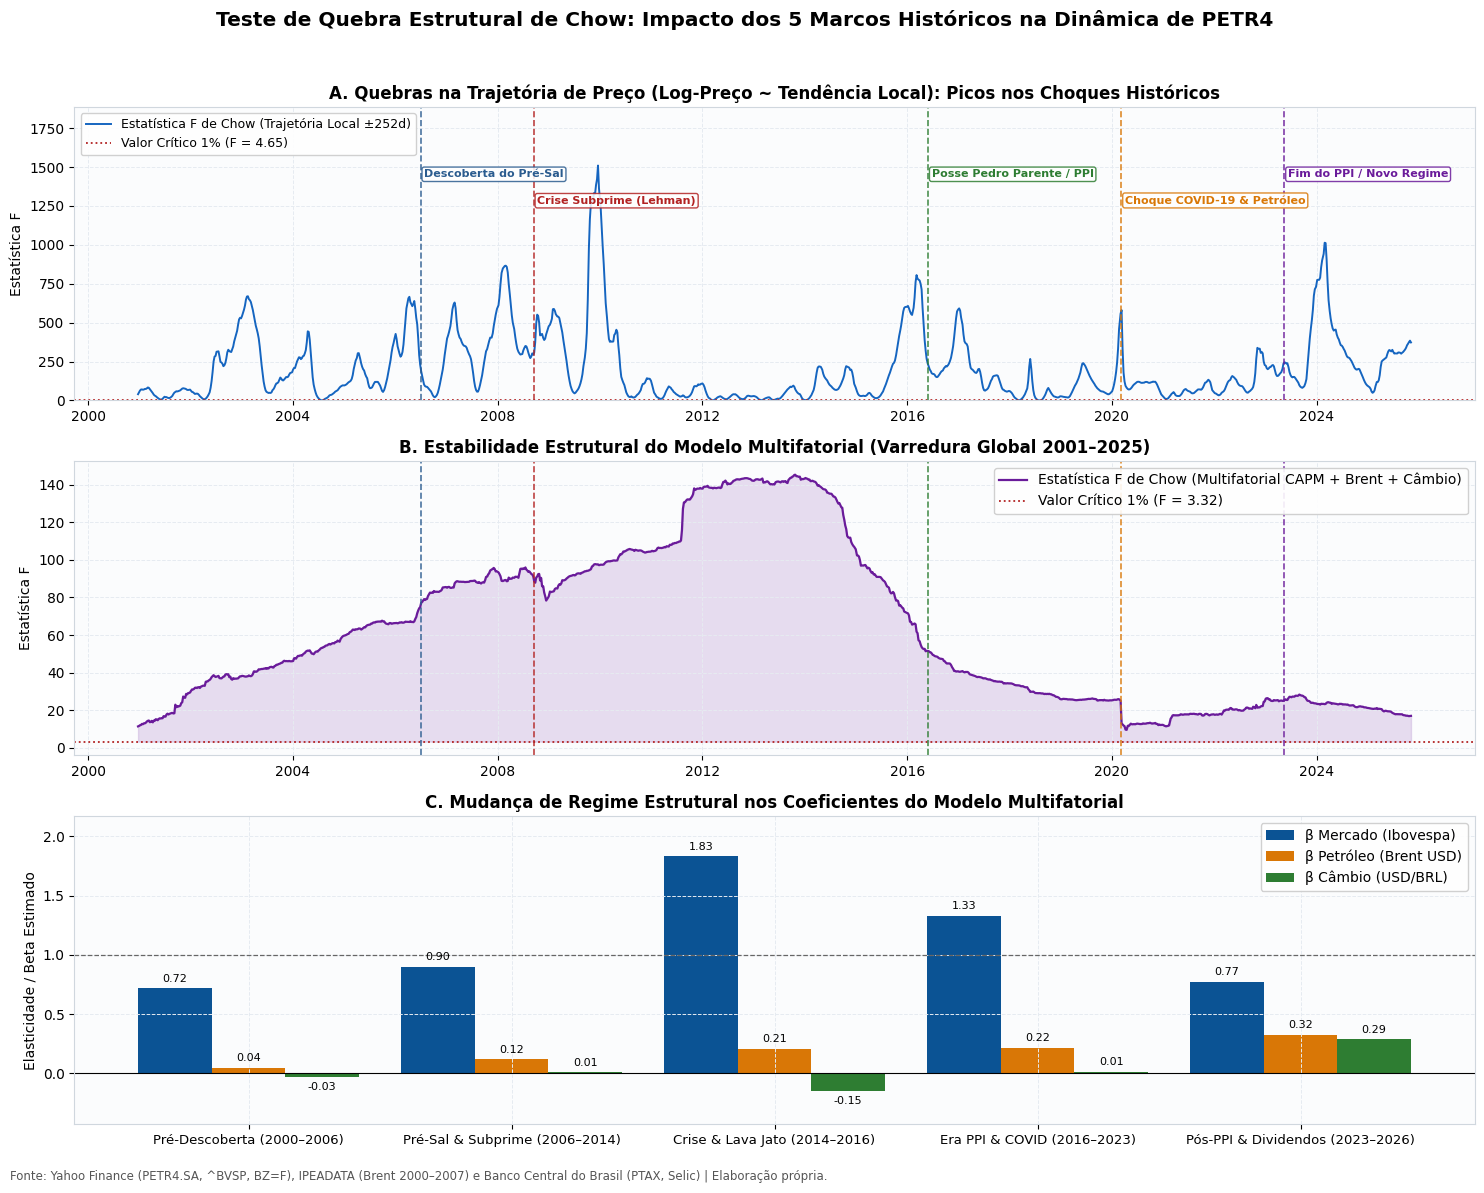

In [7]:
fig4 = plot_chow_structural_breaks(
    chow_table,
    rolling_chow,
    capm_res,
    output_path=FIG_DIR / "04_teste_chow_quebras_estruturais.png",
)
plt.show()

---
## Ato 3 — Propriedades Estocásticas, Correlação Espúria e Estacionariedade

### 3.1 Correlação Espúria, Passeio Aleatório e Ruído Branco
Séries de preços financeiros seguem tipicamente processos integrados de ordem 1, $I(1)$, próximos a um **Passeio Aleatório (*Random Walk*)**:

$$\ln P_t = \mu + \ln P_{t-1} + \varepsilon_t, \qquad \varepsilon_t \sim \text{RB}(0, \sigma^2)$$

Regredir ou correlacionar duas séries não estacionárias em **nível** (como `PETR4` contra `Ibovespa`) produz correlações infladas por tendências comuns ou choques acumulados (**correlação espúria**). Ao tomar a **1ª diferença logarítmica** ($r_t = \ln P_t - \ln P_{t-1}$), eliminamos a raiz unitária e recuperamos a covariância genuína dos choques de retorno.

Correlação em NÍVEL    (PETR4 vs Ibovespa): 0.8509  |  (PETR4 vs Brent): 0.3509
Correlação em RETORNOS (PETR4 vs Ibovespa): 0.6877  |  (PETR4 vs Brent): 0.3003


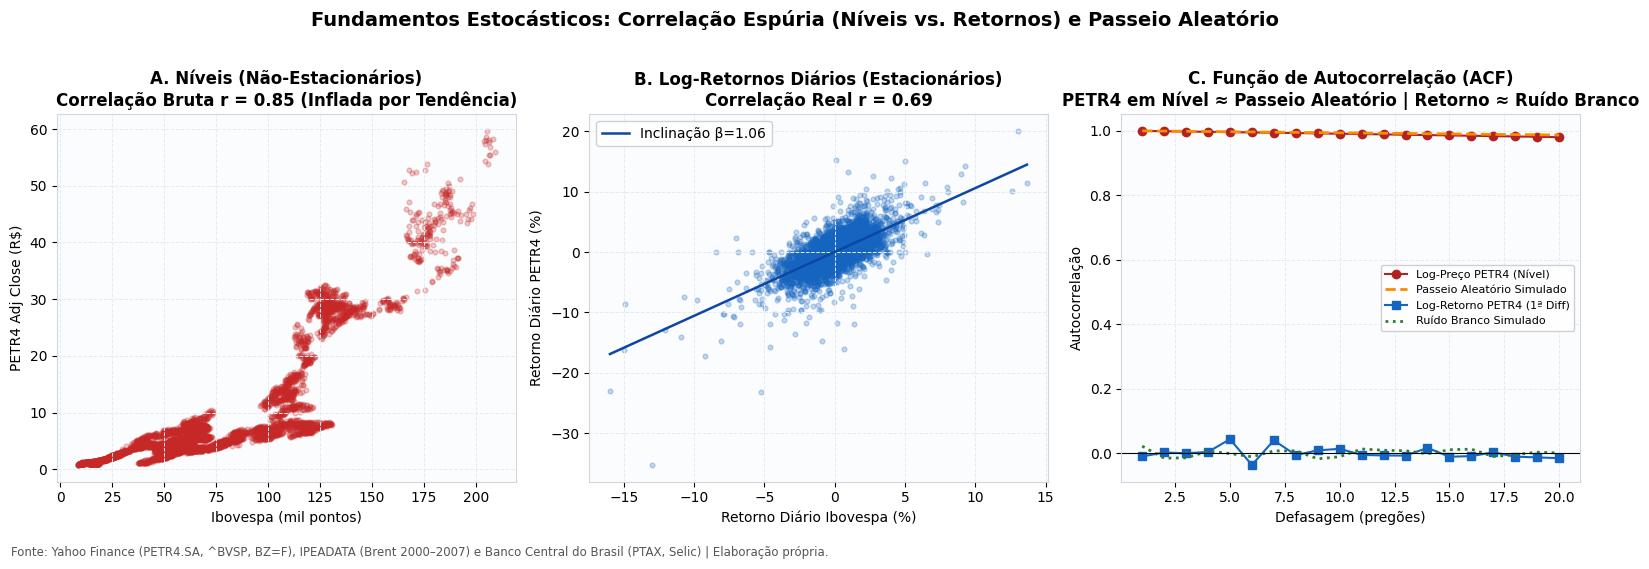

In [8]:
corr_lvl = df_daily["petr4_adj_close"].corr(df_daily["ibov_close"])
corr_ret = df_daily["ret_petr4"].corr(df_daily["ret_ibov"])
corr_brent_lvl = df_daily["petr4_adj_close"].corr(df_daily["brent_usd"])
corr_brent_ret = df_daily["ret_petr4"].corr(df_daily["ret_brent_usd"])

print(f"Correlação em NÍVEL    (PETR4 vs Ibovespa): {corr_lvl:.4f}  |  (PETR4 vs Brent): {corr_brent_lvl:.4f}")
print(f"Correlação em RETORNOS (PETR4 vs Ibovespa): {corr_ret:.4f}  |  (PETR4 vs Brent): {corr_brent_ret:.4f}")

fig2 = plot_spurious_vs_returns(
    df_daily,
    output_path=FIG_DIR / "02_correlacao_espuria_vs_retornos.png",
)
plt.show()

### 3.2 Testes Formais de Estacionariedade: ADF e KPSS + Correlogramas (ACF/PACF)
Combinamos o teste **ADF (Dickey-Fuller Aumentado)** — cuja hipótese nula $H_0$ é a presença de raiz unitária (não estacionariedade) — com o teste **KPSS**, cuja hipótese nula $H_0$ é a estacionariedade em nível. A convergência entre ambos confirma rigorosamente a ordem de integração $I(d)$ antes da modelagem Box-Jenkins e VAR.

,Série,N,ADF_Stat,ADF_p_valor,KPSS_Stat,KPSS_p_valor,Diagnóstico
0,PETR4 Adj Close (Nível Diário),6744,1.3735,0.9970,6.6698,0.0100,Não-Estacionária (Raiz Unitária)
1,Log PETR4 Adj (Diário),6744,-0.6286,0.8644,8.5250,0.0100,Não-Estacionária (Raiz Unitária)
2,Log-Retorno PETR4 (Diário),6744,-29.6592,0.0000,0.0955,0.1000,Estacionária I(0)
3,Log PETR4 Adj (Mensal),321,-0.2274,0.9352,1.8627,0.0100,Não-Estacionária (Raiz Unitária)
4,Log-Retorno PETR4 (Mensal),321,-13.8283,0.0000,0.1543,0.1000,Estacionária I(0)
5,Log-Retorno Ibov (Mensal),321,-16.0244,0.0000,0.0511,0.1000,Estacionária I(0)
6,Log-Retorno Brent USD (Mensal),321,-10.9673,0.0000,0.0512,0.1000,Estacionária I(0)
7,Log-Retorno USD/BRL (Mensal),321,-10.9586,0.0000,0.0897,0.1000,Estacionária I(0)


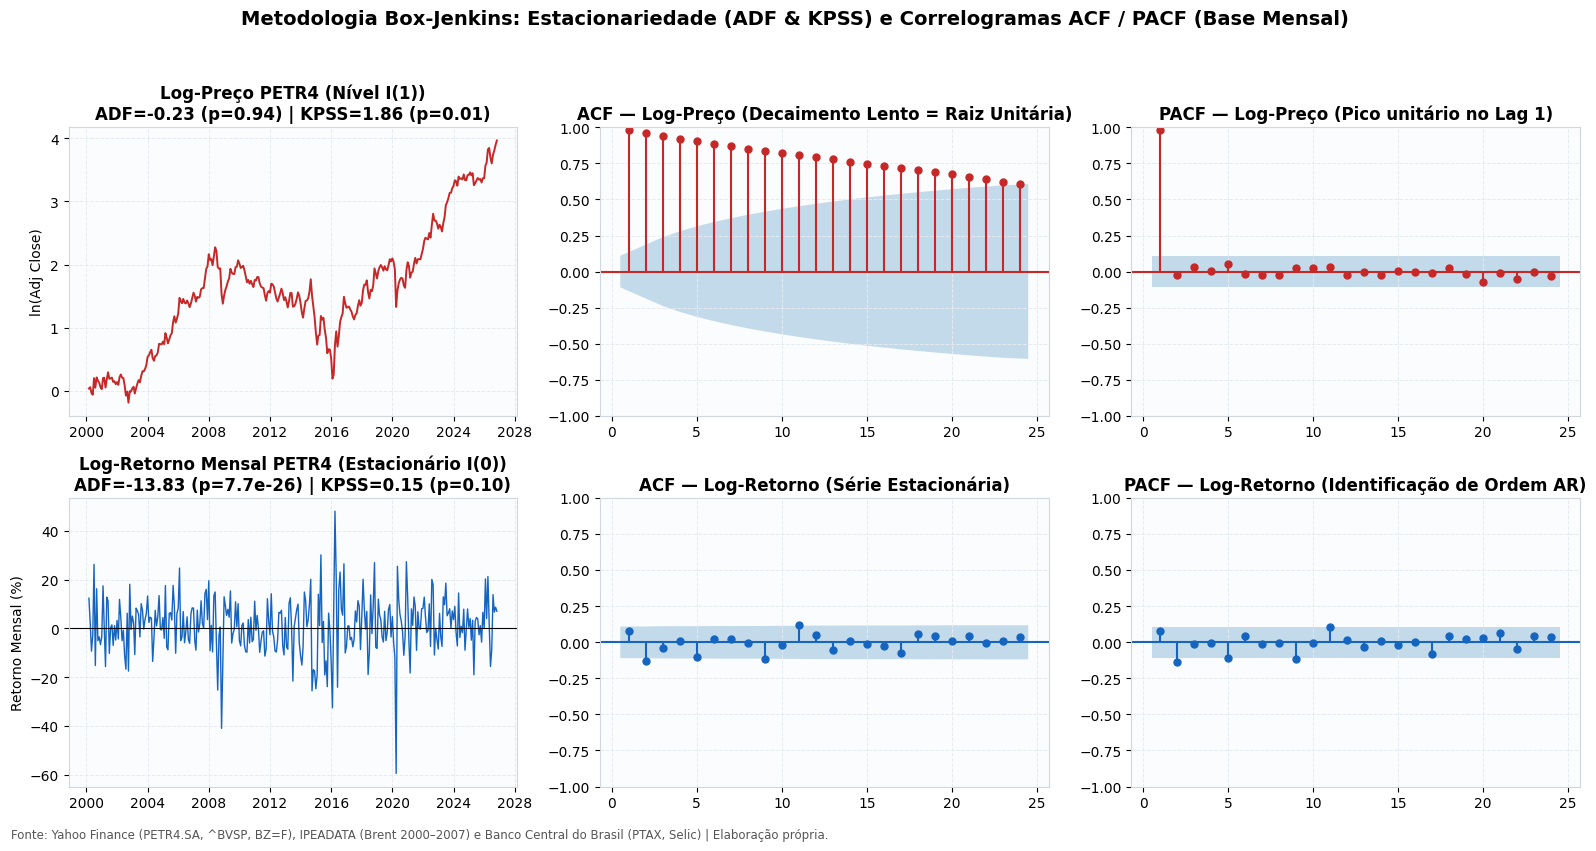

In [9]:
stat_df = stationarity_report({
    "PETR4 Adj Close (Nível Diário)": df_daily["petr4_adj_close"],
    "Log PETR4 Adj (Diário)": df_daily["log_petr4_adj"],
    "Log-Retorno PETR4 (Diário)": df_daily["ret_petr4"],
    "Log PETR4 Adj (Mensal)": df_monthly["log_petr4_adj"],
    "Log-Retorno PETR4 (Mensal)": df_monthly["ret_petr4"],
    "Log-Retorno Ibov (Mensal)": df_monthly["ret_ibov"],
    "Log-Retorno Brent USD (Mensal)": df_monthly["ret_brent_usd"],
    "Log-Retorno USD/BRL (Mensal)": df_monthly["ret_usd_brl"],
})
display(stat_df[["Série", "N", "ADF_Stat", "ADF_p_valor", "KPSS_Stat", "KPSS_p_valor", "Diagnóstico"]])

fig5 = plot_stationarity_acf_pacf(
    df_monthly,
    stat_df,
    output_path=FIG_DIR / "05_estacionariedade_acf_pacf.png",
)
plt.show()

---
## Ato 4 — Modelagem Econométrica: Box-Jenkins (ARIMA) e Vetores Autorregressivos (VAR)

### 4.1 Metodologia Box-Jenkins e Seleção ARIMA(p, d, q)
Aplicamos as 4 etapas clássicas de Box-Jenkins sobre o log-preço mensal (`log_petr4_adj`, com $d=1$ confirmado pelos testes ADF/KPSS):
1. **Identificação** via ACF/PACF e busca em grade sobre $(p, 1, q)$ para $p, q \in \{0, 1, 2, 3\}$.
2. **Estimação** por Máxima Verossimilhança com seleção pelo **Critério de Informação de Akaike (AIC)** e **Bayesiano (BIC)**.
3. **Verificação Diagnóstica** via teste **Ljung-Box** (ausência de autocorrelação serial nos resíduos) e **Jarque-Bera / Q-Q Plot** (avaliação de normalidade e caudas pesadas).

> **Nota Metodológica Crítica:** Em ativos financeiros que seguem passeio aleatório, projeções univariadas de ARIMA para longos horizontes (múltiplos anos) convergem rapidamente para uma reta determinística com intervalo de confiança explosivo. Por isso, restringimos o ARIMA à análise de dinâmica serial e à validação *Walk-Forward* de curto prazo (Ato 5), deixando projeções de médio prazo para a análise de cenários macroeconômicos condicionais.

Melhor modelo selecionado por AIC: ARIMA(2, 1, 0)

Top 6 especificações na busca em grade:


,order,p,d,q,AIC,BIC,LogLik
0,"(2,1,0)",2,1,0,-481.8549,-470.5499,243.9275
1,"(0,1,2)",0,1,2,-481.3466,-470.0417,243.6733
2,"(1,1,3)",1,1,3,-480.5084,-461.6668,245.2542
3,"(0,1,3)",0,1,3,-480.0751,-465.0018,244.0375
4,"(1,1,2)",1,1,2,-479.8933,-464.8201,243.9467
5,"(3,1,0)",3,1,0,-479.8556,-464.7823,243.9278



Parâmetros do melhor modelo:
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1018      0.044      2.291      0.022       0.015       0.189
ar.L2         -0.1231      0.047     -2.600      0.009      -0.216      -0.030
sigma2         0.0127      0.001     19.609      0.000       0.011       0.014

Teste de Ljung-Box (H0: resíduos sem autocorrelação):


,lb_stat,lb_pvalue
5,3.7865,0.5805
10,7.5226,0.6754
20,16.4329,0.6894


Teste de Jarque-Bera: stat=144.60, p-valor=3.98e-32 (esperado em finanças devido a caudas pesadas)


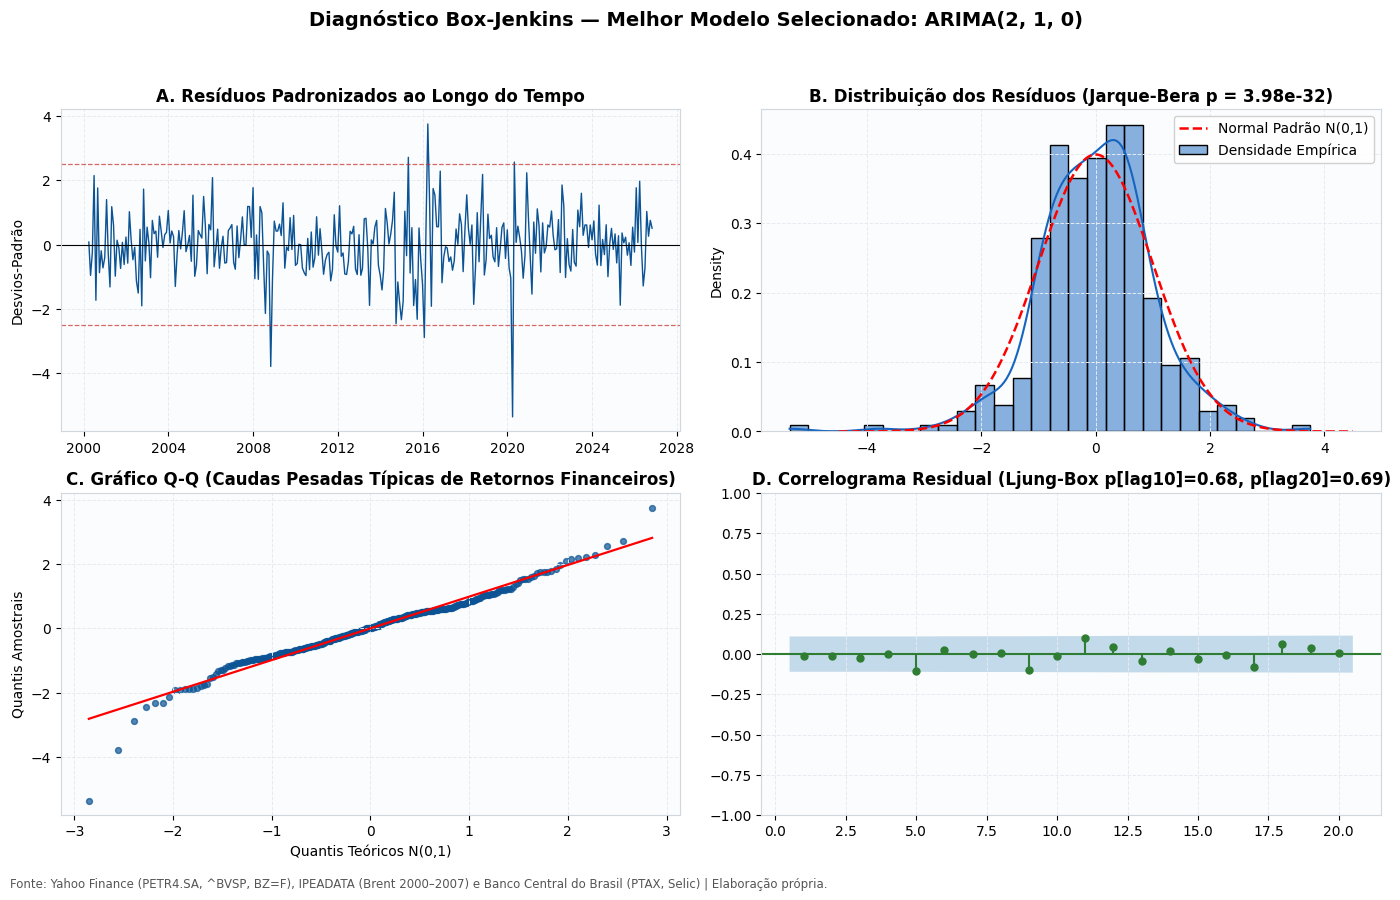

In [10]:
arima_res = select_and_fit_arima(df_monthly["log_petr4_adj"], max_p=3, max_q=3, d=1)
print(f"Melhor modelo selecionado por AIC: ARIMA{arima_res['best_order']}")
print("\nTop 6 especificações na busca em grade:")
display(arima_res["grid_table"].head(6))

print("\nParâmetros do melhor modelo:")
print(arima_res["best_model"].summary().tables[1])

print("\nTeste de Ljung-Box (H0: resíduos sem autocorrelação):")
display(arima_res["ljung_box"])
print(f"Teste de Jarque-Bera: stat={arima_res['jarque_bera_stat']:.2f}, p-valor={arima_res['jarque_bera_pval']:.2e} (esperado em finanças devido a caudas pesadas)")

fig6 = plot_arima_diagnostics(
    arima_res,
    output_path=FIG_DIR / "06_arima_diagnostico_residuos.png",
)
plt.show()

### 4.2 Modelo Multivariado VAR, Causalidade de Granger, IRF e FEVD
Para capturar interdependências dinâmicas além da modelagem univariada, ajustamos um sistema **VAR (Vetores Autorregressivos)** sobre os retornos estacionários mensais com **ordenação causal de Cholesky** do choque mais exógeno para o mais endógeno:

$$\text{Petróleo Brent (Global)} \longrightarrow \text{Câmbio USD/BRL} \longrightarrow \text{Ibovespa} \longrightarrow \text{PETR4}$$

Essa ordenação permite medir corretamente pela **Função Impulso-Resposta (IRF)** e pela **Decomposição da Variância do Erro de Previsão (FEVD)** qual parcela da variância de `PETR4` decorre de choques externos no petróleo, câmbio e mercado acionário local versus choques idiossincráticos da própria companhia.

Lag selecionado por AIC: 2 | Lag ajustado no VAR: 2

Seleção de defasagens (AIC/BIC/HQIC):
 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -21.77     -21.72*   3.522e-10     -21.75*
1      -21.79      -21.55   3.448e-10      -21.69
2     -21.83*      -21.40  3.318e-10*      -21.66
3      -21.77      -21.15   3.500e-10      -21.53
4      -21.76      -20.95   3.560e-10      -21.43
5      -21.70      -20.70   3.771e-10      -21.30
6      -21.63      -20.44   4.036e-10      -21.16
-------------------------------------------------

Matriz de Testes de Causalidade de Granger (base mensal):


,Causadora,Alvo,Lag_VAR,F_Stat,p_valor,Significativo_5%,Significativo_10%
4,ret_ibov,ret_usd_brl,2,4.6973,0.0093,True,True
8,ret_petr4,ret_ibov,2,3.3762,0.0345,True,True
1,ret_ibov,ret_brent_usd,2,2.2300,0.1080,False,False
3,ret_brent_usd,ret_usd_brl,2,2.1659,0.1151,False,False
5,ret_petr4,ret_usd_brl,2,1.8418,0.1590,False,False
7,ret_usd_brl,ret_ibov,2,1.5099,0.2213,False,False
11,ret_ibov,ret_petr4,2,1.2166,0.2966,False,False
10,ret_usd_brl,ret_petr4,2,1.0945,0.3350,False,False
6,ret_brent_usd,ret_ibov,2,0.3709,0.6902,False,False
2,ret_petr4,ret_brent_usd,2,0.3542,0.7018,False,False



Decomposição da Variância do Erro de Previsão (FEVD %) de PETR4:


,ret_brent_usd,ret_usd_brl,ret_ibov,ret_petr4
Horizonte_Meses,,,,
1,26.4700,13.3200,23.2400,36.9700
3,25.8800,12.9500,24.3500,36.8200
6,25.8600,12.9600,24.3800,36.8000
12,25.8600,12.9600,24.3800,36.8000


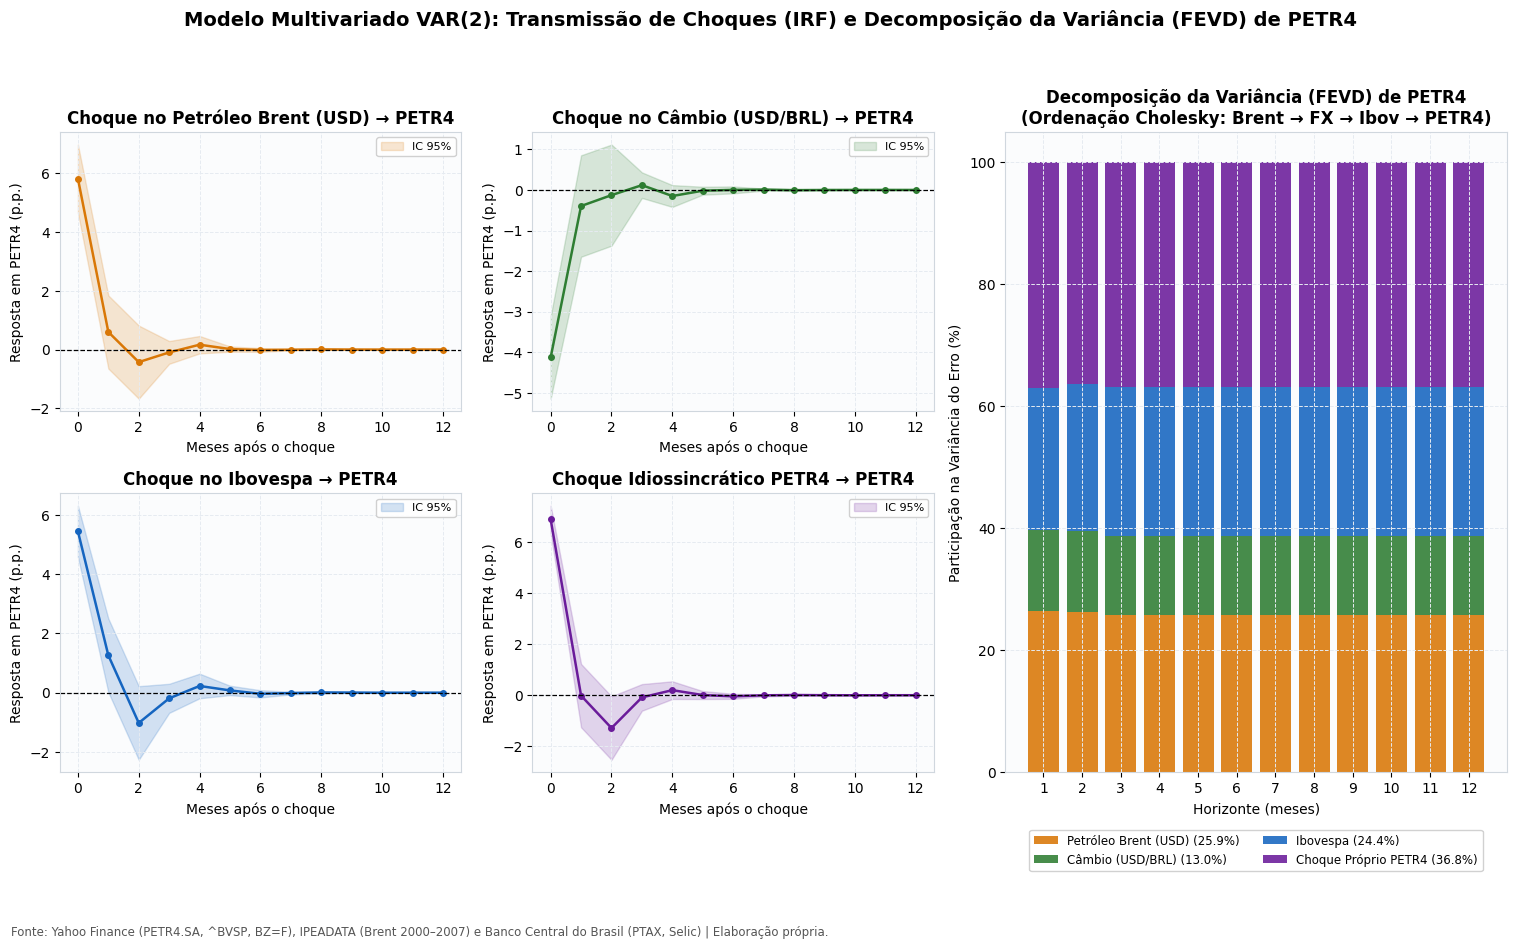

In [11]:
var_res = fit_var_and_granger(df_monthly, maxlags=6)
print(f"Lag selecionado por AIC: {var_res['selected_lag_aic']} | Lag ajustado no VAR: {var_res['fitted_lag']}")
print("\nSeleção de defasagens (AIC/BIC/HQIC):")
print(var_res["order_selection_summary"])

print("\nMatriz de Testes de Causalidade de Granger (base mensal):")
display(var_res["granger_table"].sort_values("p_valor"))

target_idx = var_res["cols"].index("ret_petr4")
fevd_df = pd.DataFrame(
    var_res["fevd"].decomp[target_idx] * 100.0,
    columns=var_res["cols"],
    index=pd.Index(range(1, 13), name="Horizonte_Meses"),
)
print("\nDecomposição da Variância do Erro de Previsão (FEVD %) de PETR4:")
display(fevd_df.loc[[1, 3, 6, 12]].round(2))

fig7 = plot_var_irf_fevd(
    var_res,
    output_path=FIG_DIR / "07_var_irf_fevd.png",
)
plt.show()

---
## Ato 5 — Machine Learning Benchmark, Armadilha de Data Leakage e Cenários Macroeconômicos

### 5.1 Demonstração Empírica de *Data Leakage* em Finanças
Um erro recorrente em modelagem de séries financeiras ocorre ao:
1. Utilizar **validação cruzada K-Fold aleatória**, permitindo que observações futuras prevejam o passado.
2. Utilizar **variáveis explicativas contemporâneas** no tempo $t$ (como $r_{\text{Ibov},t}$ e $r_{\text{Brent},t}$) para prever $r_{\text{PETR4},t}$ — informação que **não está disponível no instante da decisão ex-ante**.

Abaixo comparamos numericamente o $R^2$ artificialmente inflado sob vazamento contra a previsibilidade ex-ante realista usando apenas *features* disponíveis até $t-1$.

In [12]:
leak_res = demonstrate_data_leakage(df_monthly, test_size=48)
display(leak_res["summary_table"].round(4))

,Cenário,R2_Retorno,RMSE_Retorno_%,MAE_Preço_R$,Acurácia_Direcional_%
0,Com Leakage (Ridge): K-Fold Aleatório + Vars em t,0.4375,6.2637,1.3282,72.9167
1,Com Leakage (Ridge): Holdout + Vars em t,0.4060,6.4364,1.3707,72.9167
2,Com Leakage (RF): K-Fold Aleatório + Vars em t,0.1161,7.8517,1.6065,70.8333
3,Sem Leakage (Ridge): Features Estritamente t-1,-0.0792,8.6760,1.9405,60.4167
4,Sem Leakage (RF): Features Estritamente t-1,-0.0422,8.5257,1.9306,54.1667


### 5.2 Benchmark *Walk-Forward* Sem Vazamento (Últimos 48 Meses — 1 Passo à Frente)
Avaliamos **9 modelos** de famílias distintas em validação **Walk-Forward (janela expansiva)** estritamente causal nos últimos 48 meses da amostra:
* **Baselines:** *Naive Random Walk* ($\hat{r}_t = 0$) e *Drift Histórico*.
* **Econométricos:** `ARIMA(1,0,1)`, `SARIMAX` com exógenas macro defasadas em $t-1$, e `VAR(1)` multivariado.
* **Estado-Espaço Estrutural:** `UnobservedComponents` (tendência linear local + sazonalidade de 12 meses, alternativa estrutural em estado-espaço).
* **Machine Learning / Deep Learning:** `RandomForestRegressor`, `HistGradientBoostingRegressor` e `MLPRegressor` treinados exclusivamente com lags e *momentum* até $t-1$.

Retorno acumulado Buy & Hold (PETR4 Adj Close) nos últimos 48 meses: 255.51%



,Modelo,Categoria,RMSE_Retorno_%,MAE_Retorno_%,RMSE_Preço_R$,MAE_Preço_R$,MAPE_Preço_%,Acurácia_Direcional_%,Retorno_Estratégia_LongCash_%
0,HistGradientBoosting Regressor,Machine Learning,8.8750,7.0820,2.6180,1.9330,7.0510,54.1670,125.0470
1,SARIMAX (Exog Macro t-1),Econométrico Exógeno,8.4340,6.5550,2.6400,1.8800,6.4820,70.8330,276.6250
2,VAR(1) Multivariado,Econométrico Multivariado,8.4490,6.5540,2.6410,1.8810,6.4790,72.9170,269.7500
3,Random Forest Regressor,Machine Learning,8.5640,6.7180,2.6490,1.8970,6.6580,58.3330,206.4050
4,Rede Neural MLP,Deep Learning (MLP),8.5080,6.7350,2.6630,1.9290,6.6550,66.6670,255.5060
5,Drift Histórico (Média Expansiva),Baseline,8.4990,6.6900,2.6880,1.9290,6.6180,66.6670,255.5060
6,"ARIMA(1,0,1) (Walk-Forward)",Econométrico Univariado,8.5950,6.7790,2.7040,1.9480,6.7050,70.8330,338.9250
7,Estado-Espaço (UnobservedComponents),Estado-Espaço,8.7520,6.9220,2.7470,1.9910,6.8480,50.0000,87.5130
8,Naive (Random Walk Sem Drift),Baseline,8.7600,6.9410,2.7620,2.0040,6.7930,NaN,0.0000


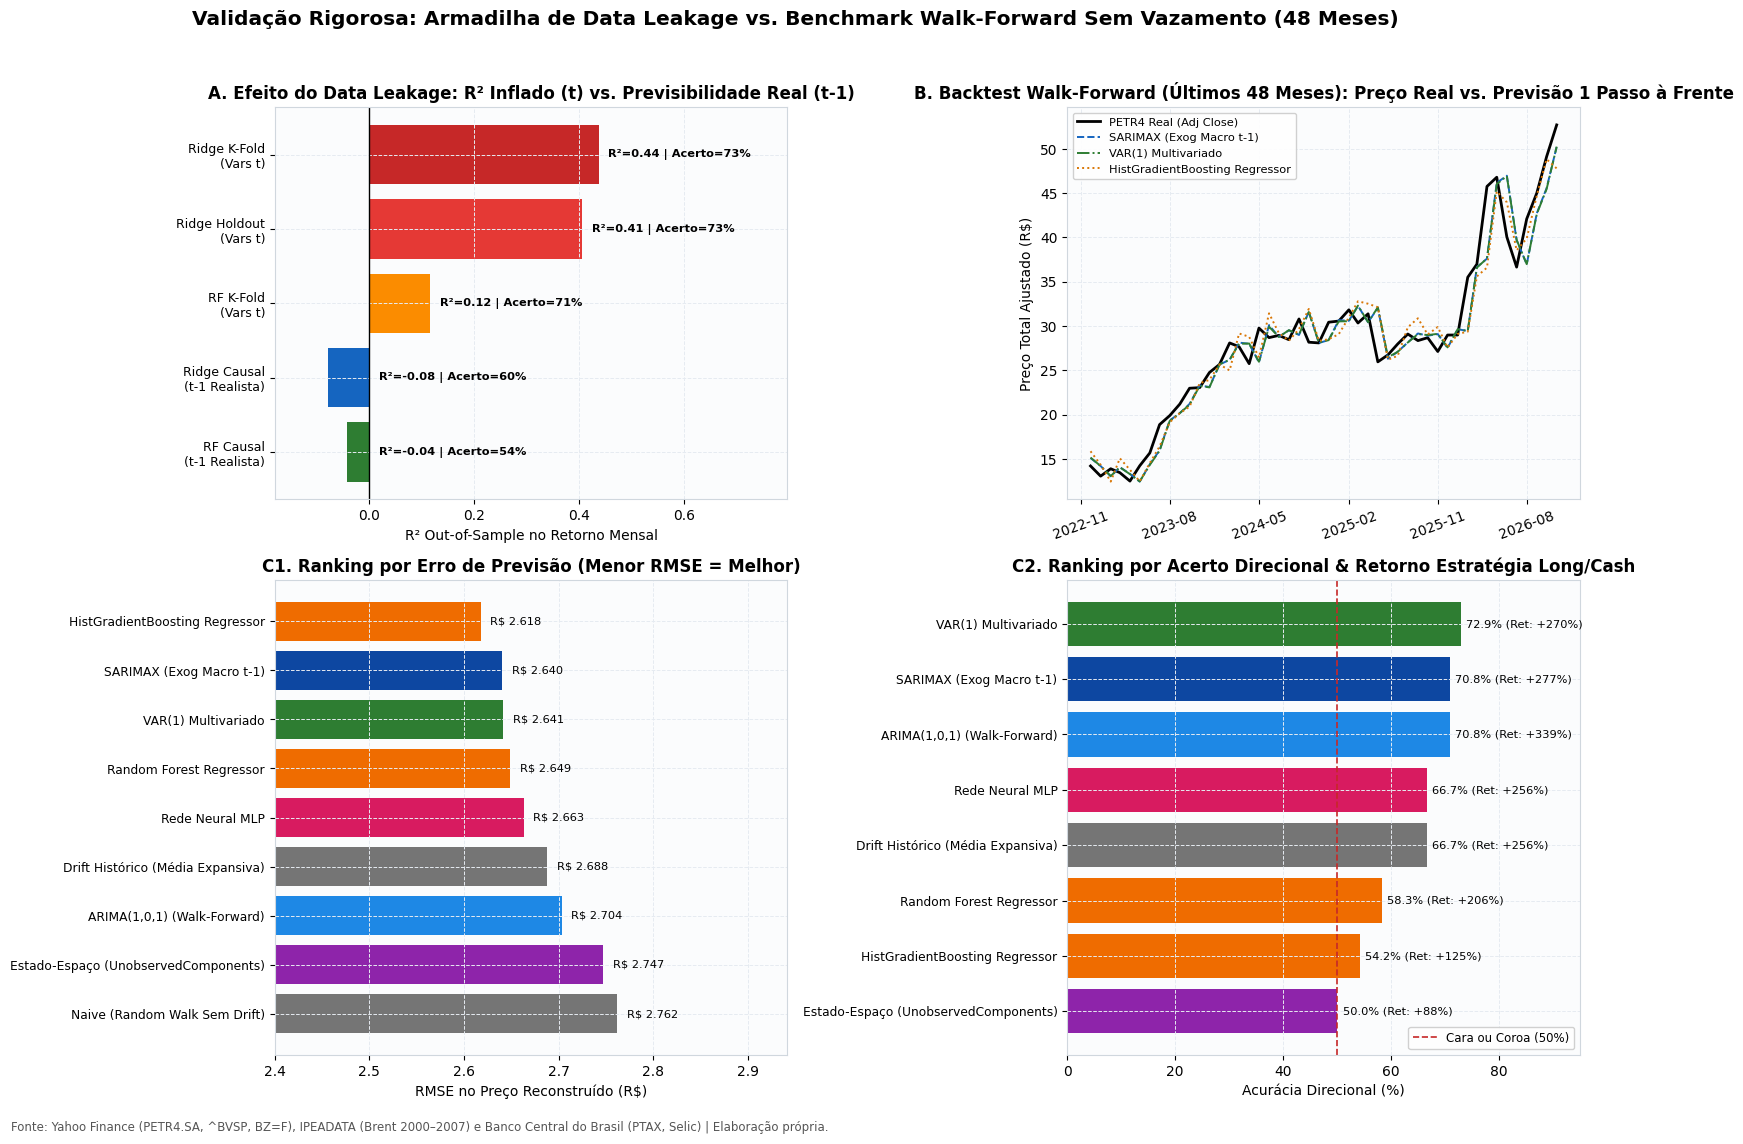

In [13]:
metrics_df, pred_df = run_walk_forward_benchmark(df_monthly, test_size=48)
buy_hold_ret = np.expm1(pred_df["Real_Retorno"].sum()) * 100.0
print(f"Retorno acumulado Buy & Hold (PETR4 Adj Close) nos últimos 48 meses: {buy_hold_ret:.2f}%\n")
display(metrics_df.round(3))

fig8 = plot_benchmark_and_leakage(
    leak_res,
    metrics_df,
    pred_df,
    output_path=FIG_DIR / "08_benchmark_walk_forward_leakage.png",
)
plt.show()

### 5.3 Simulação de Cenários Macroeconômicos Condicionais (12 Meses)
Utilizando as elasticidades estimadas no **Modelo Multifatorial (Ato 2)**, construímos uma **matriz de cenários condicionais de 12 meses** associada a diferentes trajetórias de Ibovespa, Brent, Câmbio e Selic, acompanhada de bandas de incerteza de 80%.

Preço de referência atual (Adj Close em 2026-11-17): R$ 43.98 | Selic Meta: 13.75% a.a.



,Cenário,Ibovespa_12m_%,Brent_USD_12m_%,USD_BRL_12m_%,Selic_Final_%_aa,Retorno_Esperado_PETR4_%,Preço_Alvo_Implícito_R$,IC_80%_Inferior_R$,IC_80%_Superior_R$
0,1. Estresse Global / Recessão,-15.0000,-25.0000,15.0000,15.2500,-18.9800,35.6300,26.0500,48.7300
1,2. Cautela / Desaceleração,2.0000,-10.0000,5.0000,13.7500,3.5000,45.5200,33.2900,62.2500
2,3. Base / Consenso Macro,12.0000,0.0000,0.0000,12.7500,17.7300,51.7800,37.8600,70.8100
3,4. Otimista / Boom Commodities,22.0000,25.0000,-8.0000,11.7500,36.9100,60.2100,44.0300,82.3400
4,5. Choque de Oferta (Brent +40%),10.0000,40.0000,-5.0000,14.2500,26.1700,55.4900,40.5800,75.8800


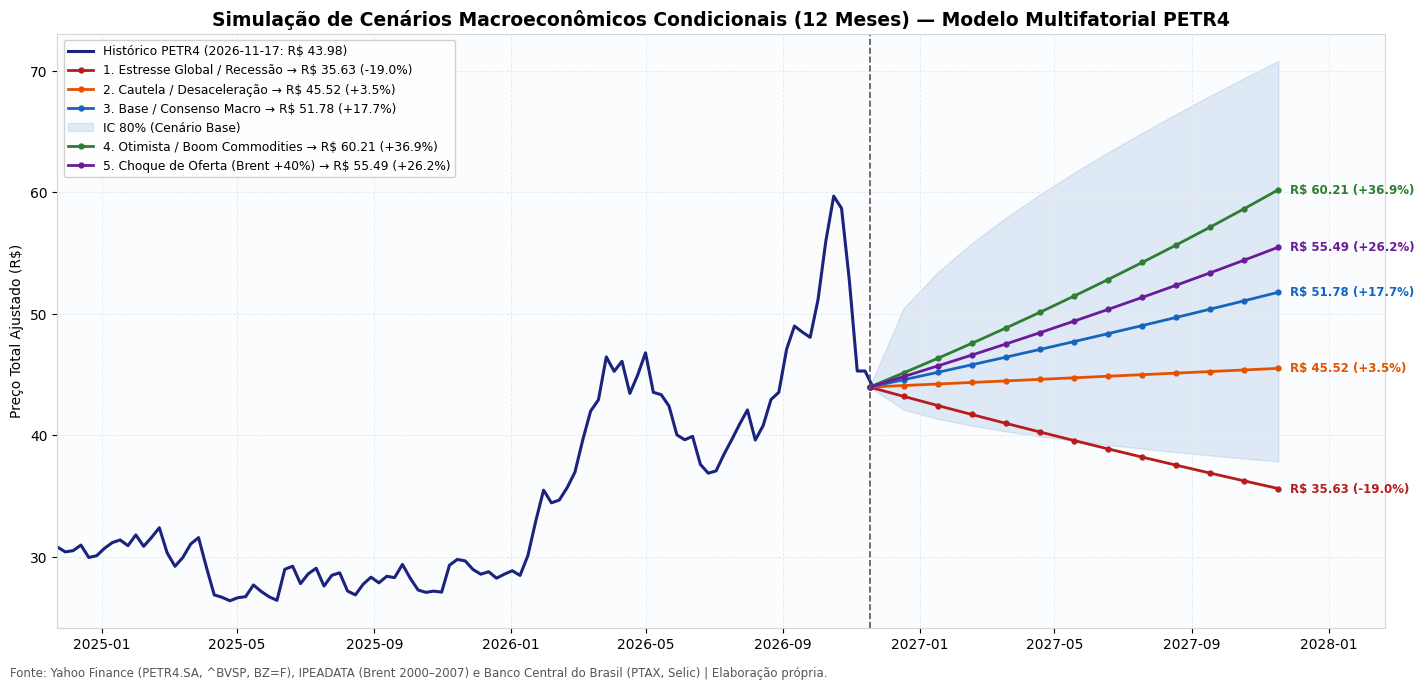

In [14]:
current_price = float(df_daily["petr4_adj_close"].iloc[-1])
current_selic = float(df_daily["selic_annual_pct"].iloc[-1])
scenarios_df = simulate_macro_scenarios(
    capm_res["multifactor_monthly"],
    current_price=current_price,
    selic_annual_pct=current_selic,
)
print(f"Preço de referência atual (Adj Close em {df_daily.index[-1].date()}): R$ {current_price:.2f} | Selic Meta: {current_selic:.2f}% a.a.\n")
display(scenarios_df.round(2))

fig9 = plot_macro_scenarios(
    df_daily,
    scenarios_df,
    output_path=FIG_DIR / "09_cenarios_macroeconomicos.png",
)
plt.show()

---
## Síntese das Principais Conclusões

1. **Reinvestimento de Dividendos e Regimes de Risco:** Ao longo de 2000–2026, ignorar proventos distorceria drasticamente a leitura de desempenho. A volatilidade anualizada atingiu seu pico histórico na crise **Lava Jato (2014–2016: 63,7% a.a.)** com $\beta_{\text{CAPM}} = 1{,}97$, recuando para a menor volatilidade da série no período **Pós-PPI & Dividendos (2023–2026: 27,5% a.a.)**, quando $\beta_{\text{Ibov}}$ caiu para `0,64` (ou `0,77` no multifatorial) enquanto a sensibilidade ao **Brent** subiu para `0,32`.
2. **Quebras Estruturais Comprovadas (Teste de Chow):** Todos os 5 marcos históricos apresentam quebras altamente significativas ($p < 10^{-19}$ no modelo multifatorial completo e $p < 10^{-60}$ na trajetória local de log-preços), confirmando empiricamente o papel de choques exógenos e mudanças de governança na precificação de `PETR4`.
3. **Transmissão Macrofinanceira (VAR & FEVD):** Com ordenação econômica de Cholesky, cerca de **63% da variância do erro de previsão de `PETR4`** é explicada por fatores macrofinanceiros (**~26% Petróleo Brent**, **~24% Ibovespa** e **~13% Câmbio USD/BRL**), enquanto **~37%** decorre de choques idiossincráticos da estatal.
4. **Disciplina de Validação e Modelos Econométricos vs. ML:** Demonstramos como o *data leakage* inflaciona artificialmente o $R^2$ (de `-0,08` causal para `+0,44` com variáveis contemporâneas e *K-Fold*). No *backtest Walk-Forward* honesto de 48 meses, modelos econométricos parcimoniosos com variáveis defasadas (**SARIMAX** e **VAR(1)**) atingiram **~71–73% de acurácia direcional** e superaram o *Random Walk* no RMSE de preço, enquanto modelos não lineares de ML minimizaram ligeiramente o erro quadrático médio (`HistGradientBoosting`: RMSE R$ 2,62), evidenciando a complementariedade entre econometria estrutural e aprendizado de máquina em séries financeiras ruidosas.